# 10 — Generalisation to FD002, FD003 and FD004

**Project:** Predictive Intelligence · **Phase 9, part 2**

## Objective

Everything so far was built and judged on FD001, the simplest subset. A method that only works on the easiest case is not much of a method. This notebook takes the pipeline to the other three subsets and asks:

1. What breaks when engines fly in six different conditions, and how do we fix it?
2. How well does the same recipe work on each subset?
3. Can a model trained on one subset be used on another?
4. Do neural networks, including a Transformer, do better on the harder subsets, as notebook 06 suggested they might?
5. Do the prediction ranges from notebook 09 still hold their promised coverage?

| Subset | Flight conditions | Fault modes | Train / test engines |
|---|---:|---:|---|
| FD001 | 1 | 1 (HPC) | 100 / 100 |
| FD002 | 6 | 1 (HPC) | 260 / 259 |
| FD003 | 1 | 2 (HPC, fan) | 100 / 100 |
| FD004 | 6 | 2 (HPC, fan) | 249 / 248 |

**Protocol.** The recipe (features, RUL cap of 125, XGBoost settings) is carried over from FD001 unchanged. Nothing is tuned on the new subsets. The only addition is the flight-condition step in section 2, which is required for the data to make sense at all. Each test set is scored once.

> **Data note.** C-MAPSS is simulated turbofan data, not telemetry from real aircraft.

## 1. Setup

The neural networks in section 6 take about an hour on a laptop CPU the first time. Finished runs are cached in `models/deep_generalisation/` and reloaded afterwards; set `RETRAIN = True` to train again.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(project_root))

from src import config
from src.data.cmapss import SENSOR_INFO, add_training_rul, load_subset
from src.data.prepare import COMMON_SENSORS, prepare_subset
from src.data.splits import engine_folds, holdout_engine_split
from src.evaluation.metrics import mae, nasa_score, rmse
from src.features.build import make_windows
from src.features.regimes import assign_regime
from src.models.networks import MLPRegressor, RecurrentRegressor, TransformerRegressor, count_parameters
from src.models.training import predict_rul, train_network
from src.models.uncertainty import calibrated_band, conformal_correction, conformity_scores, make_quantile_model, raw_band
from src.visualization import theme

theme.apply_theme()
warnings.filterwarnings("ignore", category=FutureWarning)

RETRAIN = False
CAP = config.RUL_CAP
SUBSETS = ["FD001", "FD002", "FD003", "FD004"]


def make_xgb() -> XGBRegressor:
    # The untuned settings used throughout the project.
    return XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                        colsample_bytree=0.8, n_jobs=-1, random_state=config.RANDOM_SEED)

## 2. The problem with six flight conditions

In FD002 and FD004 every cycle is flown in one of six conditions (combinations of altitude, Mach number and throttle), and the condition changes from one cycle to the next. A sensor reading depends on the condition far more than on wear. Flying at 42,000 ft instead of sea level changes the fan-inlet air and with it nearly every temperature, pressure and speed in the engine.

The chart shows one FD002 engine. On the left, the raw readings of one sensor: they jump between six levels and the wear trend is invisible. An everyday comparison: trying to judge whether someone is getting a fever when the thermometer is sometimes read in a sauna and sometimes in a freezer.

**The fix: judge each reading against what is normal for its own flight condition.** For every condition and every sensor we compute the average and the spread *on the training engines*, then express each reading as "how many standard deviations above or below normal for this condition". This is **regime normalisation**. On the right, the same sensor after normalisation: the jumps are gone and the drift is visible.

For FD001 and FD003, which have one condition, the same code simply performs ordinary standardisation. One recipe therefore serves all four subsets.

**When it can fail.** It needs the flight condition to be known and to be one of those seen in training; the code stops with an error on an unknown condition instead of guessing. It also assumes wear shifts a sensor by a similar number of standard deviations in every condition, which is an approximation.

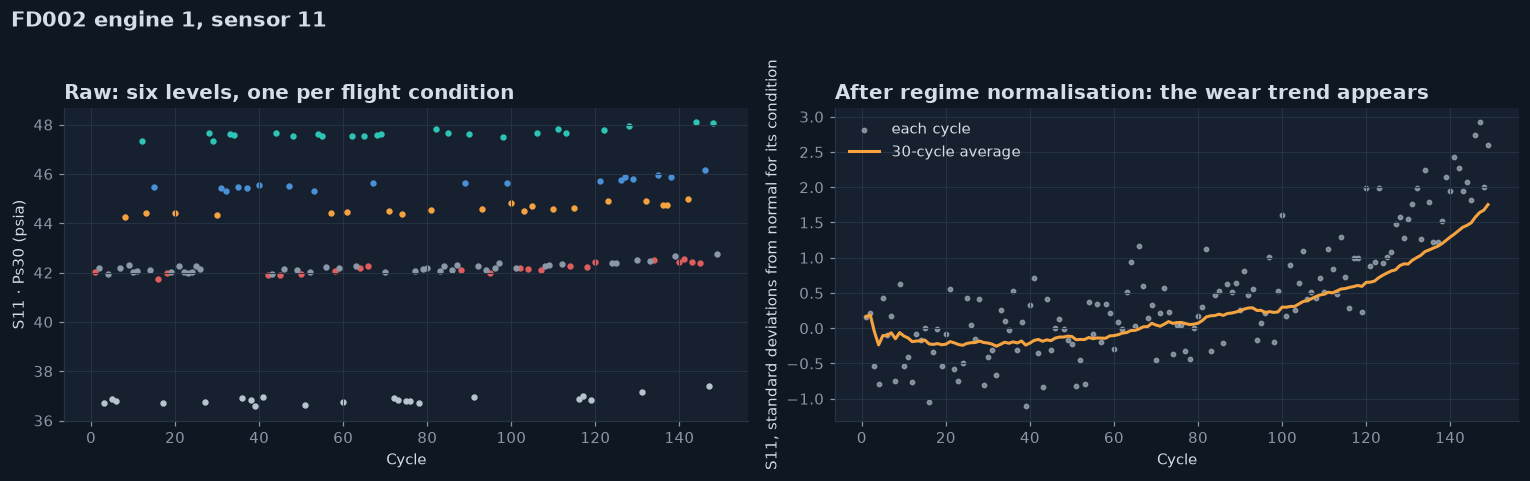

In [2]:
fd002_train, _, _ = load_subset("FD002")
fd002_prepared = prepare_subset("FD002")
example_engine = 1
raw_engine = fd002_train[fd002_train["engine_id"] == example_engine]
normalised_engine = fd002_prepared["train"][fd002_prepared["train"]["engine_id"] == example_engine]
regimes = assign_regime(raw_engine)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for regime_name, colour in zip(sorted(regimes.unique()), theme.PALETTE + [theme.MUTED]):
    rows = regimes == regime_name
    axes[0].scatter(raw_engine.loc[rows, "cycle"], raw_engine.loc[rows, "sensor_11"], s=10, color=colour)
axes[0].set_title("Raw: six levels, one per flight condition")
axes[0].set_xlabel("Cycle")
axes[0].set_ylabel("S11 · Ps30 (psia)")

axes[1].scatter(normalised_engine["cycle"], normalised_engine["sensor_11"], s=8, color=theme.SILVER, alpha=0.6, label="each cycle")
axes[1].plot(normalised_engine["cycle"], normalised_engine["sensor_11_mean30"], color=theme.AMBER, linewidth=2, label="30-cycle average")
axes[1].set_title("After regime normalisation: the wear trend appears")
axes[1].set_xlabel("Cycle")
axes[1].set_ylabel("S11, standard deviations from normal for its condition")
axes[1].legend(loc="upper left")
fig.suptitle(f"FD002 engine {example_engine}, sensor 11", x=0.01, ha="left", fontsize=14, fontweight="bold", color=theme.TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

In [3]:
prepared = {subset: prepare_subset(subset) for subset in SUBSETS}
unnormalised = {subset: prepare_subset(subset, normalise=False) for subset in SUBSETS}

trend_rows = {}
for subset in SUBSETS:
    before, after = unnormalised[subset]["train"], prepared[subset]["train"]
    trend_rows[subset] = {
        "flight conditions": assign_regime(load_subset(subset)[0]).nunique(),
        "training rows": len(after),
        "typical sensor trend with RUL, raw": before[COMMON_SENSORS].corrwith(before["rul"], method="spearman").abs().median(),
        "typical sensor trend with RUL, normalised": after[COMMON_SENSORS].corrwith(after["rul"], method="spearman").abs().median(),
        "shortest test history (cycles)": prepared[subset]["test"].groupby("engine_id").size().min(),
    }
pd.DataFrame(trend_rows).T.round(3)

,flight conditions,training rows,"typical sensor trend with RUL, raw","typical sensor trend with RUL, normalised",shortest test history (cycles)
FD001,1.0,20631.0,0.629,0.629,31.0
FD002,6.0,53759.0,0.081,0.475,21.0
FD003,1.0,24720.0,0.589,0.589,38.0
FD004,6.0,61249.0,0.096,0.528,19.0


**Findings.**

- In FD002 and FD004 the raw sensors show almost no relationship with remaining life: a typical rank correlation of about 0.08 to 0.10, against about 0.6 in the single-condition subsets. The wear signal is buried under the flight-condition jumps.
- After regime normalisation the typical correlation is 0.48 (FD002) and 0.53 (FD004). Most of the signal is recovered, though not all of it: the multi-condition subsets remain somewhat harder.
- For FD001 and FD003 the numbers are unchanged, as expected, since there is only one condition to normalise within.
- The shortest test histories in FD002 and FD004 are 21 and 19 flights. Those engines have barely enough data for the 20-flight baseline and fewer than the 30 flights of a window, so their estimates rest on thin evidence.

## 3. The same recipe on every subset

For each subset: 5-fold cross-validation on whole training engines, then one fit on all training engines and one scoring of the test set.

Fifteen sensors are used everywhere: those that vary in all four subsets. Using one fixed list is what later makes it possible to move a model between subsets. (For FD001 this adds sensor 6 to the fourteen used earlier, so its numbers differ slightly from notebook 05.)

Because the subsets have different numbers of test engines, the NASA score, which is a sum, is also shown **per engine**. Results are given against the true RUL as recorded and, for comparison with published work, against the truth capped at 125. The gap between the two is larger here than on FD001, because the true test RUL reaches about 195 in FD002 and FD004.

In [4]:
def evaluate_xgboost(data: dict) -> tuple[dict, XGBRegressor, np.ndarray]:
    train_table, features, test_last = data["train"], data["features"], data["test_last"]
    fold_scores = []
    for train_rows, validation_rows in engine_folds(train_table):
        fold_train, fold_validation = train_table.iloc[train_rows], train_table.iloc[validation_rows]
        model = make_xgb().fit(fold_train[features], fold_train["target"])
        fold_scores.append(rmse(fold_validation["target"], np.clip(model.predict(fold_validation[features]), 0, CAP)))

    model = make_xgb().fit(train_table[features], train_table["target"])
    predicted = np.clip(model.predict(test_last[features]), 0, CAP)
    truth = test_last["true_rul"].to_numpy()
    truth_capped = np.minimum(truth, CAP)
    return {
        "CV RMSE": np.mean(fold_scores), "CV fold spread": np.std(fold_scores),
        "test RMSE": rmse(truth, predicted), "test MAE": mae(truth, predicted),
        "NASA score": nasa_score(truth, predicted), "NASA score per engine": nasa_score(truth, predicted) / len(truth),
        "test RMSE (truth capped)": rmse(truth_capped, predicted),
        "NASA per engine (truth capped)": nasa_score(truth_capped, predicted) / len(truth),
        "test engines": len(truth), "engines above the cap": int((truth > CAP).sum()),
    }, model, predicted


xgb_results, xgb_models, xgb_predictions = {}, {}, {}
for subset in SUBSETS:
    xgb_results[subset], xgb_models[subset], xgb_predictions[subset] = evaluate_xgboost(prepared[subset])

within_subset = pd.DataFrame(xgb_results).T
within_subset.round(2)

,CV RMSE,CV fold spread,test RMSE,test MAE,NASA score,NASA score per engine,test RMSE (truth capped),NASA per engine (truth capped),test engines,engines above the cap
FD001,13.30,0.71,14.94,10.57,310.87,3.11,13.81,2.79,100.0,11.0
FD002,14.24,0.97,25.02,16.99,5092.48,19.66,12.81,2.63,259.0,57.0
FD003,12.33,1.09,15.53,11.68,423.60,4.24,13.99,3.79,100.0,15.0
FD004,14.39,2.01,26.37,18.62,4409.32,17.78,14.25,4.21,248.0,67.0


### How much does regime normalisation matter?

To check that the step in section 2 earns its place, the same model is trained on FD002 and FD004 in two other ways: on the raw sensors with no adjustment, and on the raw sensors with the three flight settings added as extra features so the model could work out the adjustment by itself.

In [5]:
normalisation_rows = {}
for subset in ["FD002", "FD004"]:
    raw = unnormalised[subset]
    with_settings = {**raw, "features": raw["features"] + ["setting_1", "setting_2", "setting_3"]}
    for label, data in [("raw sensors", raw), ("raw sensors + flight settings", with_settings),
                        ("regime-normalised", prepared[subset])]:
        result = xgb_results[subset] if label == "regime-normalised" else evaluate_xgboost(data)[0]
        normalisation_rows[(subset, label)] = {k: result[k] for k in ["CV RMSE", "test RMSE", "NASA score per engine"]}
pd.DataFrame(normalisation_rows).T.round(2)

CV RMSE  test RMSE  NASA score per engine
FD002 raw sensors                      19.46      29.66                  47.68
      raw sensors + flight settings    19.48      29.59                  45.14
      regime-normalised                14.24      25.02                  19.66
FD004 raw sensors                      18.33      30.37                  32.58
      raw sensors + flight settings    18.32      30.73                  37.22
      regime-normalised                14.39      26.37                  17.78

**Findings.**

- **On the comparable measure, the recipe carries over.** Cross-validation error is 12.3 to 14.4 flights on all four subsets, and test RMSE against the capped truth is 12.8 to 14.3. The pipeline built on FD001 works on the harder subsets without retuning.
- **Against the truth as recorded, FD002 and FD004 look far worse: about 25 to 26.** The reason is the cap, not the flight conditions. In those two test sets about a quarter of the engines (57 of 259 and 67 of 248) have more than 125 flights left, some as many as 195, and a model capped at 125 must miss them by up to 70. In FD001 only 11 of 100 engines are above the cap.
- Both figures are honest and they answer different questions. "How well does it estimate remaining life when wear is detectable?" About 13 to 14 flights everywhere. "How well does it estimate remaining life for any engine?" Much worse on fleets with many healthy engines, because for those the only supportable answer is "at least 125".
- **This is why comparisons with published results need care.** Many papers score against a capped truth. Quoting our 25 beside such a figure, or our 13 beside an uncapped one, would mislead in opposite directions.
- **Regime normalisation is essential, and the model cannot work it out for itself.** Without it, cross-validation error on FD002 is 19.5 instead of 14.2. Handing the model the three flight settings as extra features makes no difference at all (19.5). The adjustment has to be done before the features are built, because the rolling averages and baselines are meaningless when computed across mixed flight conditions.
- The fold spread on FD004 is 2.0, twice that of the other subsets. Results there are the least certain.

## 4. Can a model trained on one subset be used on another?

This is the harder test of generalisation. Each of the four models from section 3 is applied to each of the four test sets, giving a 4×4 table. The diagonal is the ordinary case.

**How the new engines are prepared.** The test engines are normalised with statistics from *their own subset's training engines*. That uses sensor readings only, never RUL labels, and corresponds to a realistic situation: an operator knows what normal readings look like for their own fleet, but has no failure histories to train a model on.

What to expect: FD001 engines only ever fail by HPC degradation, so a model trained on them has never seen a fan fault. FD003 and FD004 contain both.

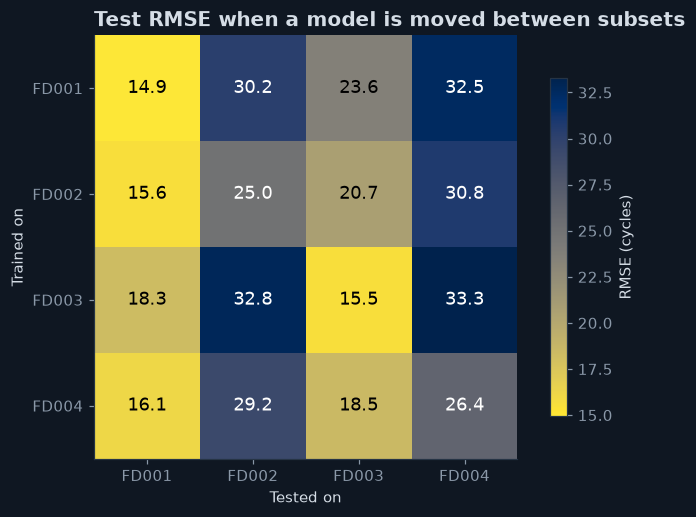

extra RMSE vs. a model trained on the same subset,FD001,FD002,FD003,FD004
trained on,,,,
FD001,0.0,5.2,8.1,6.1
FD002,0.6,0.0,5.2,4.4
FD003,3.3,7.8,0.0,6.9
FD004,1.2,4.1,3.0,0.0


In [6]:
transfer = pd.DataFrame(index=SUBSETS, columns=SUBSETS, dtype=float)
for trained_on in SUBSETS:
    for tested_on in SUBSETS:
        test_last = prepared[tested_on]["test_last"]
        predicted = np.clip(xgb_models[trained_on].predict(test_last[prepared[trained_on]["features"]]), 0, CAP)
        transfer.loc[trained_on, tested_on] = rmse(test_last["true_rul"], predicted)
transfer.index.name, transfer.columns.name = "trained on", "tested on"

fig, ax = plt.subplots(figsize=(6.6, 4.8))
image = ax.imshow(transfer.to_numpy(dtype=float), cmap="cividis_r")
ax.set_xticks(range(4), SUBSETS)
ax.set_yticks(range(4), SUBSETS)
ax.set_xlabel("Tested on")
ax.set_ylabel("Trained on")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{transfer.iloc[i, j]:.1f}", ha="center", va="center",
                color="white" if transfer.iloc[i, j] > transfer.to_numpy().mean() else "black", fontsize=12)
ax.set_title("Test RMSE when a model is moved between subsets")
ax.grid(False)
fig.colorbar(image, shrink=0.8, label="RMSE (cycles)")
fig.tight_layout()
plt.show()

penalty = transfer.sub(np.diag(transfer), axis=1)
penalty.round(1).rename_axis(index="trained on", columns="extra RMSE vs. a model trained on the same subset")

**Findings.**

- **Fault modes are the barrier, not flight conditions.** A model trained on FD001, which contains only HPC faults, is 8.1 flights worse on FD003, which also contains fan faults. It has never seen an engine fail that way.
- **Moving from six conditions to one costs almost nothing.** FD002 to FD001 loses 0.6 flights; FD004 to FD003 loses 3.0. Regime normalisation has put all engines on a common scale, so a multi-condition model reads a single-condition fleet without difficulty.
- **The most varied training set travels best.** The FD004 model, trained on six conditions and both fault modes, loses only 1.2 to 4.1 flights on the other three subsets. The FD003 model does worst when moved (up to 7.8).
- **Moving from one condition to six is costly** (FD001 to FD002: 5.2; FD003 to FD004: 6.9), even with normalisation. Normalisation equalises the *level* of each sensor across conditions but not necessarily how strongly wear shows up in each.

**What this means.** A model should be trained on data covering every way an engine is expected to fail. Missing a fault mode is far more damaging than missing a flight condition that can be normalised away. And a model applied to a fleet it was not trained on should be expected to be several flights worse than its own test results suggest.

**Caveat.** This is transfer between four subsets of one simulator, sharing the same engine model and sensors. Transfer between different real engine types would be a much harder problem.

## 5. Do the prediction ranges still hold?

Notebook 09 built 90% ranges for FD001 using conformalized quantile regression. The same procedure is repeated on each subset: out-of-fold calibration on the training engines, then a check on the test set. Coverage is measured against the capped truth, with a range ending at the cap read as "125 or more".

In [7]:
coverage_rows = {}
for subset in SUBSETS:
    train_table, features, test_last = prepared[subset]["train"], prepared[subset]["features"], prepared[subset]["test_last"]
    out_low, out_high = np.zeros(len(train_table)), np.zeros(len(train_table))
    for train_rows, held_out_rows in engine_folds(train_table):
        fold_train = train_table.iloc[train_rows]
        low_model = make_quantile_model(0.05, config.RANDOM_SEED).fit(fold_train[features], fold_train["target"])
        high_model = make_quantile_model(0.95, config.RANDOM_SEED).fit(fold_train[features], fold_train["target"])
        out_low[held_out_rows], out_high[held_out_rows] = raw_band(low_model, high_model, train_table.iloc[held_out_rows][features])

    shortest_history = prepared[subset]["test"].groupby("engine_id").size().min()
    usable = (train_table["cycle"] >= shortest_history).to_numpy()
    correction = conformal_correction(
        conformity_scores(out_low[usable], out_high[usable], train_table["target"].to_numpy()[usable]), 0.90)

    low_model = make_quantile_model(0.05, config.RANDOM_SEED).fit(train_table[features], train_table["target"])
    high_model = make_quantile_model(0.95, config.RANDOM_SEED).fit(train_table[features], train_table["target"])
    low, high = calibrated_band(*raw_band(low_model, high_model, test_last[features]), correction, 0, CAP)
    truth_capped = np.minimum(test_last["true_rul"].to_numpy(), CAP)
    covered = (truth_capped >= low) & (truth_capped <= high)
    near_failure = test_last["true_rul"].to_numpy() <= 30
    coverage_rows[subset] = {
        "conformal correction (cycles)": correction,
        "test coverage (%)": covered.mean() * 100,
        "average width (cycles)": (high - low).mean(),
        "failed sooner than range": int((truth_capped < low).sum()),
        "lasted longer than range": int((truth_capped > high).sum()),
        "coverage, true RUL up to 30 (%)": covered[near_failure].mean() * 100,
        "engines with true RUL up to 30": int(near_failure.sum()),
        "test engines": len(covered),
    }
pd.DataFrame(coverage_rows).T.round(1)

,conformal correction (cycles),test coverage (%),average width (cycles),failed sooner than range,lasted longer than range,"coverage, true RUL up to 30 (%)",engines with true RUL up to 30,test engines
FD001,0.5,95.0,44.3,3.0,2.0,88.0,25.0,100.0
FD002,-0.4,91.5,45.2,17.0,5.0,83.6,61.0,259.0
FD003,0.1,89.0,42.7,10.0,1.0,100.0,20.0,100.0
FD004,-0.4,87.1,45.6,22.0,10.0,75.5,53.0,248.0


**Findings.**

- **Overall coverage is close to the 90% target on every subset**: 95.0%, 91.5%, 89.0% and 87.1%. FD004 is slightly under. With 248 engines, a method that is exactly right would typically land between about 86% and 94%, so 87.1% is at the low edge of what chance allows.
- **The width is the same everywhere**, about 43 to 46 flights on average.
- **Near failure the picture is less comfortable on the multi-condition subsets.** For engines with 30 or fewer flights left, coverage is 83.6% on FD002 and 75.5% on FD004. On FD004, 22 engines failed sooner than their range allowed, against 10 that outlasted it.
- So the weakness seen in notebook 09 is confirmed and sharper here: **the range under-covers exactly where a miss matters most, and on the hardest subset it does so clearly.** An average guarantee over the whole fleet is not a guarantee for the engines closest to failure.

**What should follow.** For any use where near-failure engines matter most, the range should be calibrated separately for low estimates, or a higher coverage level chosen, and checked on that group specifically. That has not been done in this project. Meanwhile the assistant's rule stands: the lower end of the range is not a safety margin.

## 6. Neural networks on the harder subsets

Notebook 06 found that neural networks did not beat XGBoost on FD001, and argued that FD001 is too simple to show what they can do. The same notebook deferred the Transformer to the multi-condition, two-fault subsets, where it would have more structure to find. Here that is tested.

Three architectures, on all four subsets, with the same training recipe as notebook 06:

- **MLP** (three seeds) — the simple reference.
- **GRU** (one seed) — the best sequence model on the FD001 hold-out.
- **Transformer** (one seed) — a small encoder: each cycle becomes a 64-number vector, a learned position marker records its place in the window, and two attention layers let every cycle weigh every other cycle.

Inputs are the 15 regime-normalised sensors plus their change from baseline (30 channels), in 30-cycle windows. Twenty percent of training engines are held out for early stopping, and XGBoost is retrained on the same 80% for a like-for-like comparison.

**Read these results with care.** GRU and Transformer have a single run each, because each run takes several minutes to tens of minutes on a CPU. Notebook 06 measured a seed-to-seed spread of 0.6 to 0.9 cycles of test RMSE on FD001. A difference smaller than about 2 cycles between a single-seed network and anything else should be treated as inconclusive.

In [8]:
WINDOW = config.SEQUENCE_WINDOW
weights_dir = project_root / "models" / "deep_generalisation"
runs_dir = project_root / "experiments" / "deep_generalisation_runs"
weights_dir.mkdir(parents=True, exist_ok=True)
runs_dir.mkdir(parents=True, exist_ok=True)

delta_columns = [f"{name}_delta" for name in COMMON_SENSORS]
channels = COMMON_SENSORS + delta_columns

architectures = {
    "MLP": (lambda: MLPRegressor(WINDOW, len(channels)), [0, 1, 2]),
    "GRU": (lambda: RecurrentRegressor(len(channels), cell="gru"), [0]),
    "Transformer": (lambda: TransformerRegressor(WINDOW, len(channels)), [0]),
}


def window_data(subset: str) -> dict:
    train_table, test_table = prepared[subset]["train"], prepared[subset]["test"]
    training_engines, _ = holdout_engine_split(train_table)
    is_training = train_table["engine_id"].isin(training_engines)

    # The sensors are already regime-normalised; this second scaling puts the delta channels on the same footing.
    scaler = StandardScaler().fit(train_table.loc[is_training, channels])
    scaled_train, scaled_test = train_table.copy(), test_table.copy()
    scaled_train[channels] = scaler.transform(train_table[channels])
    scaled_test[channels] = scaler.transform(test_table[channels])

    x_train, y_train, _ = make_windows(scaled_train[is_training], channels, WINDOW, "target")
    x_validation, y_validation, _ = make_windows(scaled_train[~is_training], channels, WINDOW, "target")
    x_test, _, test_engine_ids = make_windows(scaled_test, channels, WINDOW, last_only=True)
    truth = prepared[subset]["test_last"].set_index("engine_id").loc[test_engine_ids, "true_rul"].to_numpy()
    return {"x_train": x_train, "y_train": y_train, "x_validation": x_validation, "y_validation": y_validation,
            "x_test": x_test, "truth": truth, "is_training": is_training, "test_engine_ids": test_engine_ids}


def run_or_load(subset: str, architecture: str, seed: int, data: dict):
    make_model = architectures[architecture][0]
    run_name = f"{subset.lower()}_{architecture.lower()}_seed{seed}"
    weights_path, history_path = weights_dir / f"{run_name}.pt", runs_dir / f"{run_name}.json"
    if weights_path.exists() and history_path.exists() and not RETRAIN:
        model = make_model()
        model.load_state_dict(torch.load(weights_path))
        history = json.loads(history_path.read_text())
    else:
        model, history = train_network(make_model, data["x_train"], data["y_train"], data["x_validation"],
                                       data["y_validation"], target_scale=CAP, seed=seed, max_epochs=40, patience=6)
        history["parameters"] = count_parameters(model)
        torch.save(model.state_dict(), weights_path)
        history_path.write_text(json.dumps(history, indent=1))
    return model, history


deep_rows = []
for subset in SUBSETS:
    data = window_data(subset)
    train_table, features = prepared[subset]["train"], prepared[subset]["features"]

    reference = make_xgb().fit(train_table.loc[data["is_training"], features], train_table.loc[data["is_training"], "target"])
    test_last = prepared[subset]["test_last"].set_index("engine_id").loc[data["test_engine_ids"]]
    reference_prediction = np.clip(reference.predict(test_last[features]), 0, CAP)
    deep_rows.append({"subset": subset, "model": "XGBoost (same 80% of engines)", "runs": 1,
                      "training windows": len(data["x_train"]),
                      "test RMSE": rmse(data["truth"], reference_prediction), "RMSE sd over seeds": np.nan,
                      "NASA per engine": nasa_score(data["truth"], reference_prediction) / len(data["truth"]),
                      "training minutes per run": np.nan})

    for architecture, (_, seeds) in architectures.items():
        scores, nasa, minutes = [], [], []
        for seed in seeds:
            model, history = run_or_load(subset, architecture, seed, data)
            predicted = predict_rul(model, data["x_test"], CAP)
            scores.append(rmse(data["truth"], predicted))
            nasa.append(nasa_score(data["truth"], predicted) / len(data["truth"]))
            minutes.append(history["seconds"] / 60)
        deep_rows.append({"subset": subset, "model": architecture, "runs": len(seeds),
                          "training windows": len(data["x_train"]),
                          "test RMSE": np.mean(scores), "RMSE sd over seeds": np.std(scores) if len(seeds) > 1 else np.nan,
                          "NASA per engine": np.mean(nasa), "training minutes per run": np.mean(minutes)})

deep_results = pd.DataFrame(deep_rows)
deep_results.pivot(index="model", columns="subset", values="test RMSE").loc[
    ["XGBoost (same 80% of engines)", "MLP", "GRU", "Transformer"]].round(2)

subset,FD001,FD002,FD003,FD004
model,,,,
XGBoost (same 80% of engines),14.42,25.08,15.95,26.66
MLP,16.08,25.42,15.00,27.76
GRU,16.74,23.98,14.74,26.95
Transformer,16.07,24.57,18.22,27.24


In [9]:
deep_results.set_index(["subset", "model"])[["runs", "training windows", "test RMSE", "RMSE sd over seeds",
                                               "NASA per engine", "training minutes per run"]].round(2)

runs  training windows  test RMSE  \
subset model                                                              
FD001  XGBoost (same 80% of engines)     1             14459      14.42   
       MLP                               3             14459      16.08   
       GRU                               1             14459      16.74   
       Transformer                       1             14459      16.07   
FD002  XGBoost (same 80% of engines)     1             37051      25.08   
       MLP                               3             37051      25.42   
       GRU                               1             37051      23.98   
       Transformer                       1             37051      24.57   
FD003  XGBoost (same 80% of engines)     1             17754      15.95   
       MLP                               3             17754      15.00   
       GRU                               1             17754      14.74   
       Transformer                       1             17754      18.22   
FD004  XGBoost (same 80% of engines)     1             42960      26.66   
       MLP                               3             42960      27.76   
       GRU                               1             42960      26.95   
       Transformer                       1             42960      27.24   

                                      RMSE sd over seeds  NASA per engine  \
subset model                                                                
FD001  XGBoost (same 80% of engines)                 NaN             3.02   
       MLP                                          0.38             3.66   
       GRU                                           NaN             4.01   
       Transformer                                   NaN             4.19   
FD002  XGBoost (same 80% of engines)                 NaN            20.35   
       MLP                                          0.36            19.91   
       GRU                                           NaN            14.40   
       Transformer                                   NaN            15.27   
FD003  XGBoost (same 80% of engines)                 NaN             4.61   
       MLP                                          0.40             3.41   
       GRU                                           NaN             3.97   
       Transformer                                   NaN             7.94   
FD004  XGBoost (same 80% of engines)                 NaN            18.13   
       MLP                                          0.22            21.68   
       GRU                                           NaN            21.65   
       Transformer                                   NaN            22.53   

                                      training minutes per run  
subset model                                                    
FD001  XGBoost (same 80% of engines)                       NaN  
       MLP                                                0.23  
       GRU                                                1.77  
       Transformer                                        3.12  
FD002  XGBoost (same 80% of engines)                       NaN  
       MLP                                                0.43  
       GRU                                                3.85  
       Transformer                                        8.90  
FD003  XGBoost (same 80% of engines)                       NaN  
       MLP                                                0.32  
       GRU                                                3.13  
       Transformer                                        3.73  
FD004  XGBoost (same 80% of engines)                       NaN  
       MLP                                                0.40  
       GRU                                                4.88  
       Transformer                                        7.68

**Findings.**

- **No architecture wins consistently.** XGBoost is best on FD001 (14.4) and FD004 (26.7). The GRU is best on FD002 (24.0) and FD003 (14.7). The spread between best and worst on each subset is 1.1 to 3.5 flights.
- **FD003 is the one subset with reasonable evidence for the networks.** The MLP, which has three seeds, scores 15.0 with a spread of 0.4, against 15.9 for XGBoost. The single GRU run agrees (14.7). That is about one flight better.
- **On FD002 the GRU and Transformer are about one flight better than XGBoost in RMSE** (24.0 and 24.6 against 25.1). With single runs, that is inside the margin we said beforehand we would treat as inconclusive. Their NASA score per engine is clearly lower (14.4 and 15.3 against 20.4), meaning fewer large late errors on that test set, which is worth following up with more seeds.
- **On FD004, the hardest subset, where the argument for sequence models and attention was strongest, the tree model is ahead of all three networks.**
- **The Transformer did not justify itself.** It is best on no subset, clearly worst on FD003 (18.2), and takes the longest to train. The expectation in notebook 06, that attention would pay off with six flight conditions and two fault modes, is not supported by these runs.

**Honest summary.** The claim "deep learning is better for the harder subsets" is not supported here, and neither is the opposite. With regime normalisation and the baseline features doing most of the work, all four model types land within a few flights of each other on every subset. The networks are competitive on FD002 and FD003; XGBoost is competitive everywhere, trains in seconds, and can be explained exactly.

**Limits of this comparison, which are substantial.** One seed for GRU and Transformer. No tuning of any network: one small configuration each, and a Transformer in particular is sensitive to its settings. Windows fixed at 30 flights although these subsets have longer engine lives. All scores are against the uncapped truth, where about a quarter of FD002 and FD004 engines cannot be predicted correctly by any capped model, which compresses the differences between models. A properly resourced study could reach a different conclusion.

In [10]:
experiments_dir = project_root / "experiments"
within_subset.round(4).to_csv(experiments_dir / "all_subsets_xgboost.csv", index_label="subset")
transfer.round(4).to_csv(experiments_dir / "all_subsets_transfer_rmse.csv")
pd.DataFrame(coverage_rows).T.round(4).to_csv(experiments_dir / "all_subsets_uncertainty.csv", index_label="subset")
deep_results.round(4).to_csv(experiments_dir / "all_subsets_deep.csv", index=False)
print("Saved:", sorted(p.name for p in experiments_dir.glob("all_subsets_*.csv")))

Saved: ['all_subsets_deep.csv', 'all_subsets_transfer_rmse.csv', 'all_subsets_uncertainty.csv', 'all_subsets_xgboost.csv']


## 7. Conclusions

| Question | Answer |
|---|---|
| What breaks with six flight conditions? | Raw sensors lose almost all relationship with wear (correlation about 0.08). Regime normalisation restores most of it (about 0.5) |
| Does the recipe carry over? | Yes on the comparable measure: CV error 12 to 14 flights and capped test RMSE 13 to 14 on all four subsets, with no retuning |
| Why is uncapped test RMSE 25 to 26 on FD002 and FD004? | About a quarter of their test engines are beyond the 125-flight cap |
| Can a model be moved between subsets? | From many conditions to one, nearly free. To a fleet with an unseen fault mode, up to 8 flights worse |
| Do the ranges hold? | Overall coverage 87 to 95% against a 90% target; near failure only 76 to 84% on the multi-condition subsets |
| Do neural networks win on the harder subsets? | Not consistently. Slightly better on FD003 and possibly FD002, worse on FD004. The Transformer was best on none |

**What changed in our understanding.**

1. The method generalises; the headline metric does not, unless the cap is accounted for. Any RUL result should state how the truth was treated.
2. Coverage of training data matters most for fault modes. Flight conditions can be normalised away; an unseen way of failing cannot.
3. The uncertainty ranges need attention near failure before they could support any real decision.
4. The working model (XGBoost on engineered features) remains a sound choice on all four subsets (decision D-013 stands).

**Limitations.** Nothing was tuned per subset. The cap of 125 was chosen on FD001 and may not be the best choice where engines live longer. Single seeds for two of the three networks. All four subsets come from one simulator. Flight conditions are assumed known and limited to the six seen in training.

## 8. Next steps

The analysis phases end here. What follows is the assistant, the application, and the monitoring and deployment work, all built on the FD001 model.